In [82]:
import  pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

In [83]:
Data = pd.read_csv("C:\\Users\\chync\\OneDrive\\Desktop\\tasks AI\\Task_codeveta\\level1\\task_two\\Data\\capture-fisheries-vs-aquaculture.csv")

In [84]:
df=pd.DataFrame(Data)
df

,Entity,Code,Year,Aquaculture production (metric tons),Capture fisheries production (metric tons)
0,Afghanistan,AFG,1969,60.00,400.00
1,Afghanistan,AFG,1970,60.00,400.00
2,Afghanistan,AFG,1971,60.00,500.00
3,Afghanistan,AFG,1972,60.00,500.00
4,Afghanistan,AFG,1973,60.00,500.00
...,...,...,...,...,...
14669,Zimbabwe,ZWE,1965,NaN,"2,000.00"
14670,Zimbabwe,ZWE,1966,NaN,"2,000.00"
14671,Zimbabwe,ZWE,1967,NaN,"2,000.00"
14672,Zimbabwe,ZWE,1968,NaN,"2,000.00"


In [85]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14674 entries, 0 to 14673
Data columns (total 5 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Entity                                      14674 non-null  str    
 1   Code                                        11901 non-null  str    
 2   Year                                        14674 non-null  int64  
 3   Aquaculture production (metric tons)        11657 non-null  float64
 4   Capture fisheries production (metric tons)  14516 non-null  float64
dtypes: float64(2), int64(1), str(2)
memory usage: 573.3 KB


In [86]:
df.isnull().sum()

Entity                                           0
Code                                          2773
Year                                             0
Aquaculture production (metric tons)          3017
Capture fisheries production (metric tons)     158
dtype: int64

In [87]:
df= df.dropna()


In [88]:
df.isnull().sum()

Entity                                        0
Code                                          0
Year                                          0
Aquaculture production (metric tons)          0
Capture fisheries production (metric tons)    0
dtype: int64

In [92]:
df.columns = ["entity", "code", "year", "aquaculture", "capture"] 

In [93]:
world = df[df["entity"] == "World"].copy()
countries = df[df["code"].notna() & (df["code"] != "OWID_WRL")].copy()
print("Countries:", countries["entity"].nunique(), "| rows:", len(countries))
print("Years:", countries["year"].min(), "-", countries["year"].max())

Countries: 194 | rows: 8670
Years: 1960 - 2018


In [94]:
missing_by_year = countries.groupby("year")["aquaculture"].apply(lambda s: s.isna().mean() * 100)
print(missing_by_year.loc[[1960, 1980, 2000, 2018]].round(1).astype(str) + " %")

year
1960    0.0 %
1980    0.0 %
2000    0.0 %
2018    0.0 %
Name: aquaculture, dtype: str


In [95]:
cols = ["aquaculture", "capture"]
stats = pd.DataFrame({
    "mean":   countries[cols].mean(),
    "median": countries[cols].median(),
    "mode":   [countries[c].mode()[0] for c in cols],
    "std":    countries[cols].std(),
    "min":    countries[cols].min(),
    "max":    countries[cols].max(),
})
stats

,mean,median,mode,std,min,max
aquaculture,"222,651.83",888.00,0.00,"2,415,362.74",0.00,"66,135,060.00"
capture,"485,321.07","52,317.00",0.00,"1,379,683.44",0.00,"16,647,935.00"


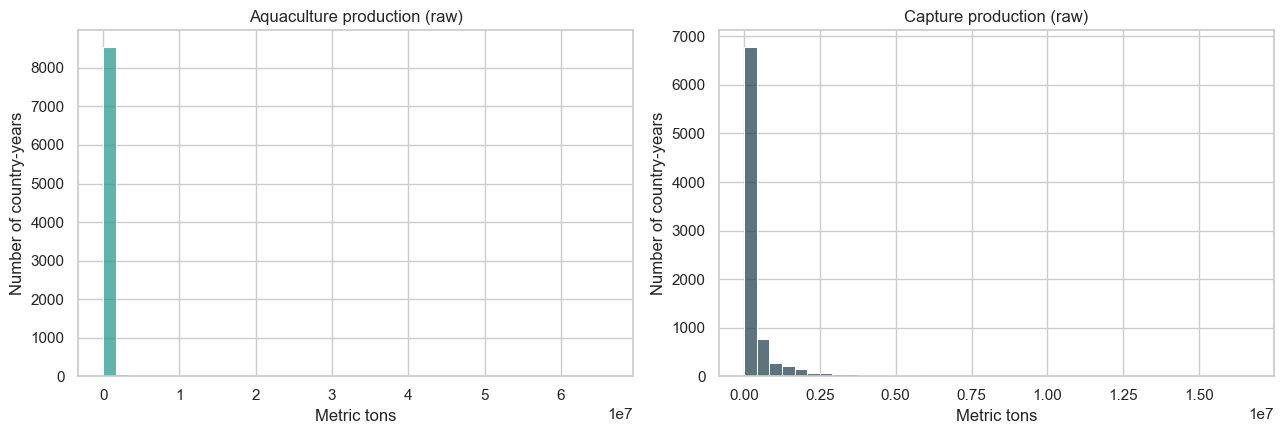

In [96]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, color in zip(axes, cols, ["#2a9d8f", "#264653"]):
    sns.histplot(countries[col].dropna(), bins=40, ax=ax, color=color)
    ax.set_title(f"{col.capitalize()} production (raw)")
    ax.set_xlabel("Metric tons")
    ax.set_ylabel("Number of country-years")
plt.tight_layout()
plt.savefig("images/01_hist_raw.png", dpi=200, bbox_inches="tight")
plt.show()

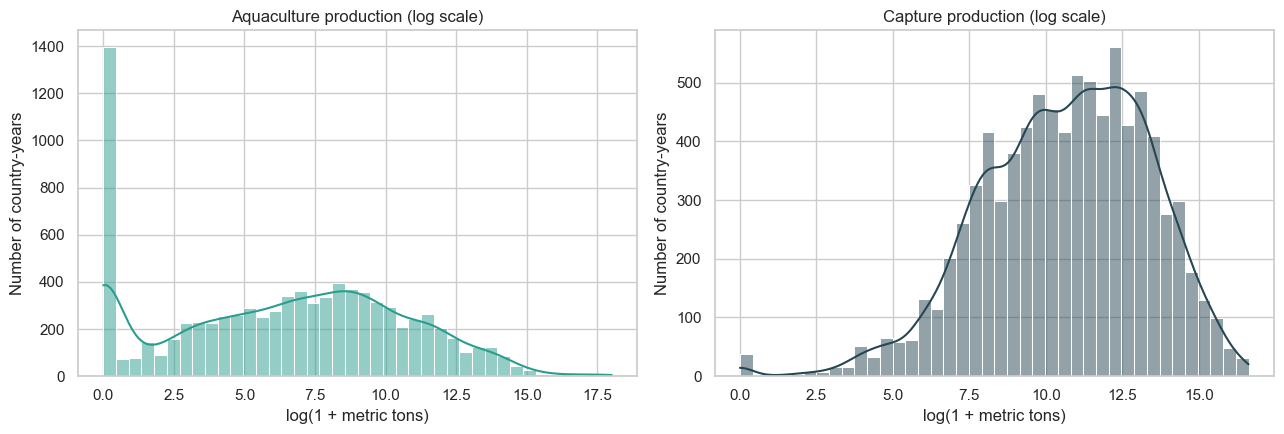

In [97]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, color in zip(axes, cols, ["#2a9d8f", "#264653"]):
    sns.histplot(np.log1p(countries[col].dropna()), bins=40, kde=True, ax=ax, color=color)
    ax.set_title(f"{col.capitalize()} production (log scale)")
    ax.set_xlabel("log(1 + metric tons)")
    ax.set_ylabel("Number of country-years")
plt.tight_layout()
plt.savefig("images/02_hist_log.png", dpi=200, bbox_inches="tight")
plt.show()

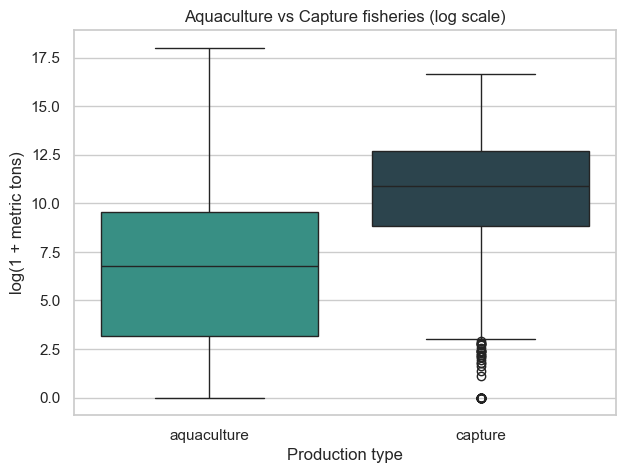

In [98]:
long = countries.melt(id_vars=["entity", "year"], value_vars=cols,
                      var_name="type", value_name="tons").dropna()
long["log_tons"] = np.log1p(long["tons"])

plt.figure(figsize=(7, 5))
sns.boxplot(data=long, x="type", y="log_tons", palette=["#2a9d8f", "#264653"], hue="type", legend=False)
plt.title("Aquaculture vs Capture fisheries (log scale)")
plt.xlabel("Production type")
plt.ylabel("log(1 + metric tons)")
plt.savefig("images/03_boxplot.png", dpi=200, bbox_inches="tight")
plt.show()

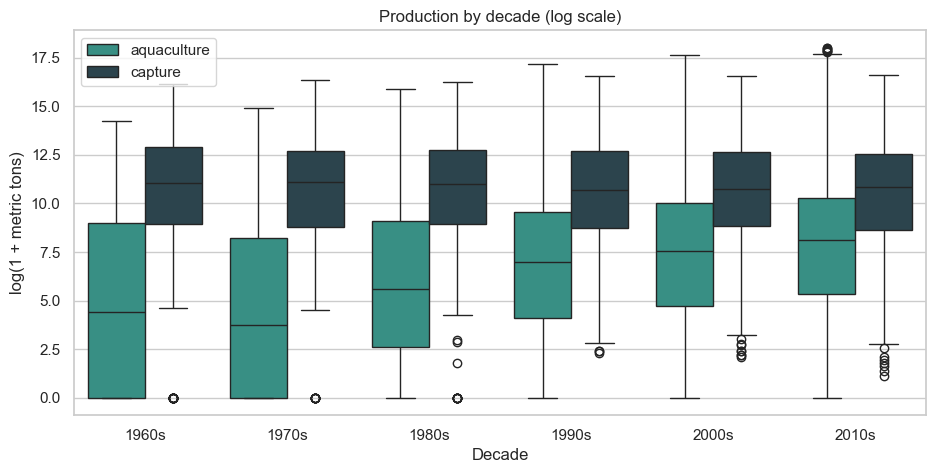

In [99]:
countries["decade"] = (countries["year"] // 10 * 10).astype(str) + "s"
dec = countries.melt(id_vars=["decade"], value_vars=cols, var_name="type", value_name="tons").dropna()
dec["log_tons"] = np.log1p(dec["tons"])

plt.figure(figsize=(11, 5))
sns.boxplot(data=dec, x="decade", y="log_tons", hue="type", palette=["#2a9d8f", "#264653"])
plt.title("Production by decade (log scale)")
plt.xlabel("Decade")
plt.ylabel("log(1 + metric tons)")
plt.legend(title="")
plt.savefig("images/04_boxplot_decade.png", dpi=200, bbox_inches="tight")
plt.show()

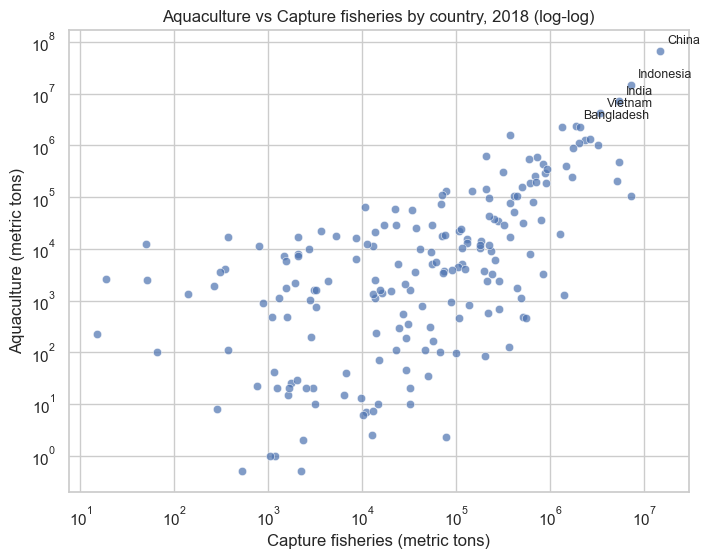

In [100]:
y18 = countries[countries["year"] == 2018].dropna(subset=cols)
plt.figure(figsize=(8, 6))
sns.scatterplot(data=y18, x="capture", y="aquaculture", alpha=0.7)
plt.xscale("log"); plt.yscale("log")
for _, r in y18.nlargest(5, "aquaculture").iterrows():
    plt.annotate(r["entity"], (r["capture"], r["aquaculture"]), fontsize=9, xytext=(5, 5), textcoords="offset points")
plt.title("Aquaculture vs Capture fisheries by country, 2018 (log-log)")
plt.xlabel("Capture fisheries (metric tons)")
plt.ylabel("Aquaculture (metric tons)")
plt.savefig("images/05_scatter_2018.png", dpi=200, bbox_inches="tight")
plt.show()

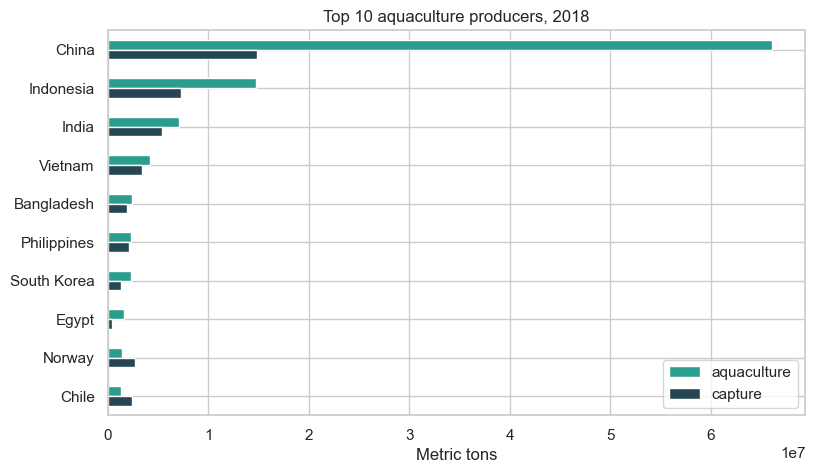

In [101]:
top = y18.nlargest(10, "aquaculture")[["entity", "aquaculture", "capture"]].set_index("entity")
top.plot(kind="barh", figsize=(9, 5), color=["#2a9d8f", "#264653"])
plt.gca().invert_yaxis()
plt.title("Top 10 aquaculture producers, 2018")
plt.xlabel("Metric tons")
plt.ylabel("")
plt.savefig("images/07_top10.png", dpi=200, bbox_inches="tight")
plt.show()

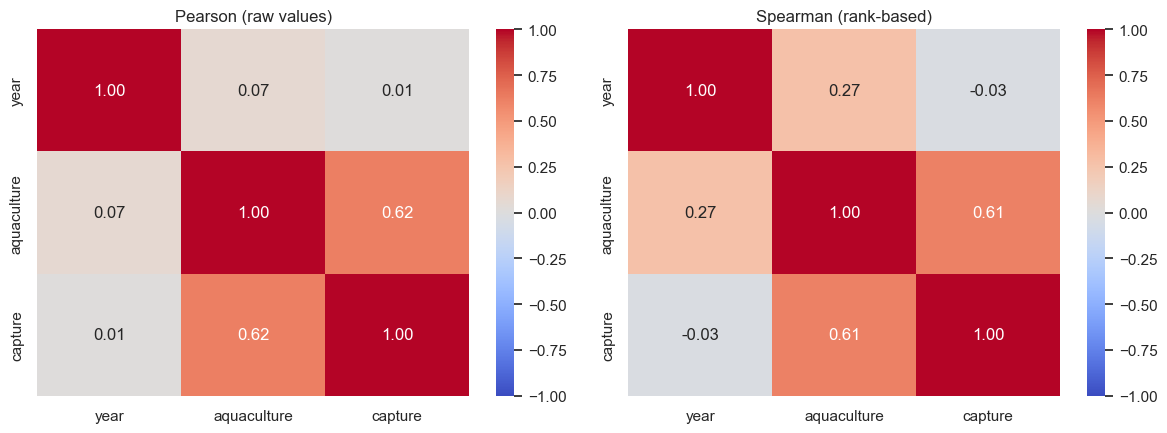

In [102]:
num = countries[["year", "aquaculture", "capture"]]
corr_pearson = num.corr(numeric_only=True)
corr_spearman = num.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(corr_pearson, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson (raw values)")
sns.heatmap(corr_spearman, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman (rank-based)")
plt.tight_layout()
plt.savefig("images/08_correlation.png", dpi=200, bbox_inches="tight")
plt.show()

In [103]:
df.to_csv("C:\\Users\\chync\\OneDrive\\Desktop\\tasks AI\\Task_codeveta\\level1\\task_two\\Data\\capture-fisheries-vs-aquaculture_cleaned.csv", index=False)